## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   --------- ------------------------------ 7.1/29.8 MB 49.6 MB/s eta 0:00:01
   --------------------------------- ------ 24.6/29.8 MB 70.0 MB/s eta 0:00:01
   ---------------------------------------  29.6/29.8 MB 66.8 MB/s eta 0:00:01
   ---------------------------------------- 29.8/29.8 MB 51.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

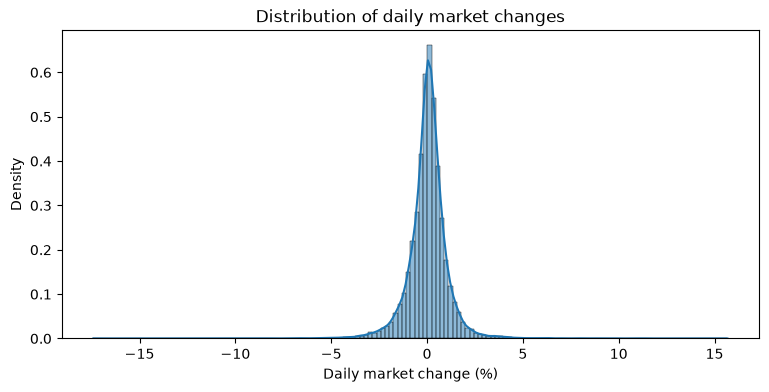

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

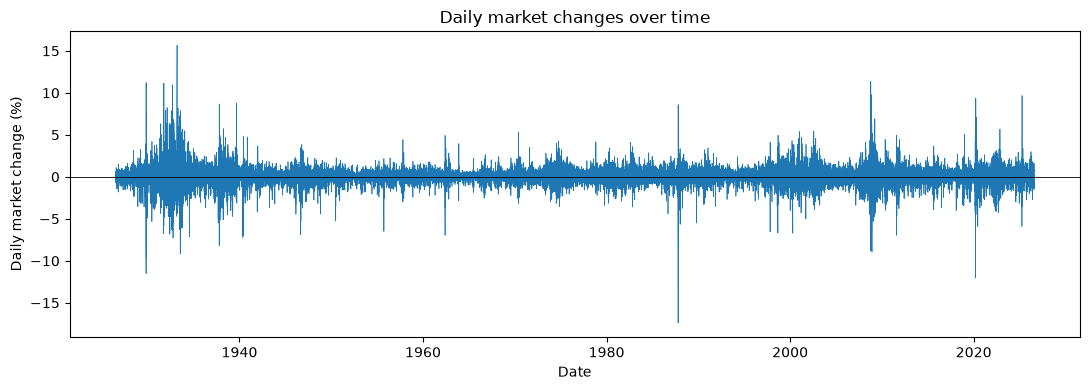

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df.columns

Index(['date', 'year', 'month', 'month_start', 'trading_day_of_month',
       'mkt_excess_return_pct', 'risk_free_return_pct', 'market_return_pct',
       'absolute_market_return_pct'],
      dtype='str')

In [6]:
df['trend'] = np.where(df['market_return_pct'] > 0, 'up', 'down')
df['current_value'] = df['market_return_pct']
df['next_value'] = df['current_value'].shift(-1)
df['current_trend'] = df['trend']
df['next_trend'] = df['current_trend'].shift(-1)

pairs = df[['current_trend', 'next_trend']].value_counts().reset_index()

In [8]:
pairs

,current_trend,next_trend,count
0,up,up,8388
1,up,down,5999
2,down,up,5999
3,down,down,5909


In [9]:
joint_pmf = pd.crosstab(df['current_trend'], df['next_trend'], normalize=True)
joint_pmf

next_trend,down,up
current_trend,,
down,0.224720,0.228142
up,0.228142,0.318996


In [10]:
marginal_pmf = pd.crosstab(df['current_trend'], df['next_trend'], 
            normalize = True, margins = True)
marginal_pmf

next_trend,down,up,All
current_trend,,,
down,0.224720,0.228142,0.452862
up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [11]:
conditional_pmf = pd.crosstab(df['current_trend'], df['next_trend'], 
            normalize = 'index')
conditional_pmf

next_trend,down,up
current_trend,,
down,0.496221,0.503779
up,0.416974,0.583026


Up transitions are more common than down transitions as shown by the marginal pmf, which has up transitions happening 54.7% of next days. The conditional pmf shows that you are more likely to transition from an up to an up (58.3%) than from a down to an up (50.4%). 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [12]:
df['return_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [13]:
df['y_t'].value_counts()

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

small gain is the most common category, large loss is the least common category.

In [14]:
joint_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all')
joint_pmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


In [16]:
marginal_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
marginal_pmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


Small gain to small gain is the most likely transition to occur happening 15.9% of the time.

In [17]:
conditional_pmf = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
conditional_pmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


**Which two future states are most likely:**

Large loss: small gain, small loss

Small loss: small gain, small loss

Near zero: small gain, small loss

Small gain: small gain, small loss

Large gain: small gain, small loss

Large loss is the only category that is relatively close to a uniform probability of 0.2. It is dificult to predict the next state, the best prediction is only right 42.8% of the time.

In [18]:
df['cond_exp'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['cond_exp'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


The mean column represents tomorrows expected return given todays current state. Large loss and large gain both have the widest range in terms of their min and max values while near zero has the smallest range. Large loss and large gain also had the largest standard deviations which shows that they have the most volatility. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
df['y_t'] = pd.qcut(df['market_return_pct'], 21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)

[Text(0.5, 1.0, 'Joint PMF')]

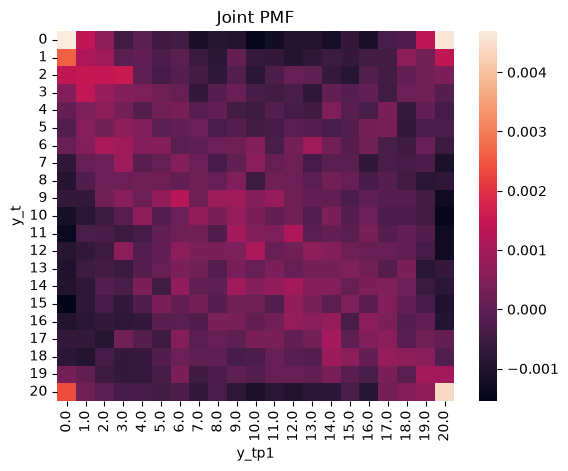

In [22]:
joint_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all')
sns.heatmap(joint_pmf - 1/21**2).set(title='Joint PMF')

The four croners have the highest probability and make an x shape on the heatmap.

[Text(0.5, 1.0, 'Conditional PMF')]

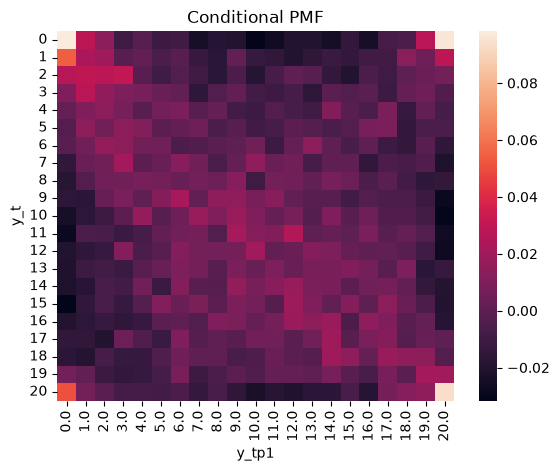

In [23]:
cond_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(cond_pmf - 1/21).set(title='Conditional PMF')

The conditional pmf has the same patterns as the joint pmf, with the corners having the highest probability, causing an x shape.

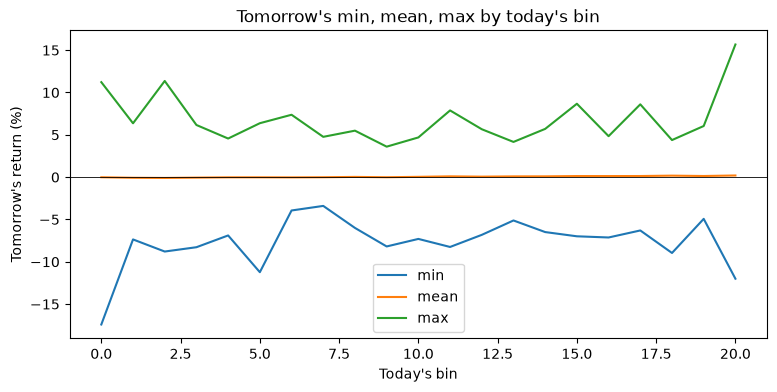

In [ ]:
bin_stats = df.groupby('y_t')['next_value'].agg(['min', 'mean', 'max', 'std'])

# Created the plot with AI, I kept getting errors so I asked the AI to debug.  
fig, ax = plt.subplots(figsize=(9, 4))
bin_stats[['min', 'mean', 'max']].plot(ax=ax)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's bin", ylabel="Tomorrow's return (%)", title="Tomorrow's min, mean, max by today's bin")
plt.show()

The mean stays consistenly close to zero, only increasing slightly at the tail end. The min and max values are at their largest at the first and last bins.

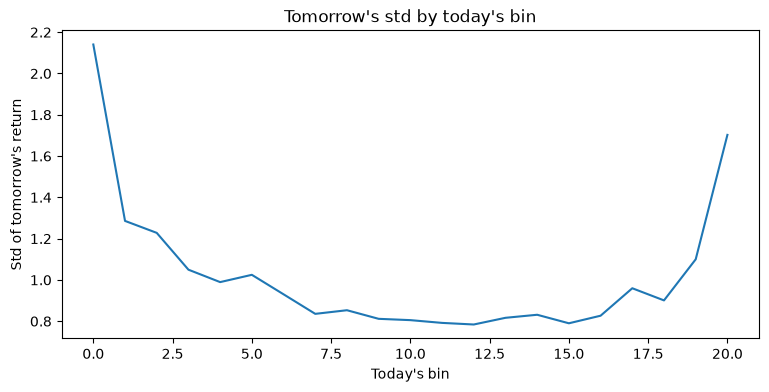

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
bin_stats['std'].plot(ax=ax)
ax.set(xlabel="Today's bin", ylabel="Std of tomorrow's return", title="Tomorrow's std by today's bin")
plt.show()

The plot forms a u shape, with the first and last bins showing the most volatility. It is very dificult to predict the market, the best prediction of tomorrow's state given today's state was only 15.9%.  